# 03 · Data Preprocessing – Làm sạch & chuẩn hoá dữ liệu
**Challenge 2 – Phân loại bài hát theo `Class`**

Nội dung:
1. Chuẩn bị & tổng hợp vấn đề từ bước EDA
2. Chuẩn hoá cột `duration` (phút / mili-giây lẫn lộn)
3. Xử lý missing values
4. Xử lý dữ liệu trùng lặp
5. Xử lý outliers
6. Encoding dữ liệu categorical
7. Scaling dữ liệu numerical
8. Pipeline hoàn chỉnh, kiểm tra & lưu kết quả
9. Tổng kết

> **Nguyên tắc chống rò rỉ dữ liệu (data leakage):** mọi thống kê (median, ngưỡng cắt outlier, mean/std) chỉ được **học từ train**
> rồi áp dụng sang test. Toàn bộ logic nằm trong `notebooks/preprocessing.py` (class `MusicPreprocessor`, dùng được trong `Pipeline` ở bước 05).

In [2]:
import warnings
warnings.filterwarnings("ignore")
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

try:
    from IPython.display import display
except ImportError:          # chạy ngoài Jupyter
    display = print

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RANDOM_STATE = 42

# Tự tìm thư mục DATA_CHALLENGE2 (đi ngược lên từ thư mục notebook)
DATA_DIR = next(p / "DATA_CHALLENGE2" for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "DATA_CHALLENGE2").exists())
sys.path.insert(0, str(DATA_DIR.parent / "notebooks"))
from preprocessing import (MusicPreprocessor, ID, TARGET, DUR, CONT_COLS, FEATURE_COLS)
from logger_utils import ExperimentLogger

train = pd.read_csv(next(DATA_DIR.glob("train*.csv")))
test = pd.read_csv(next(DATA_DIR.glob("test*.csv")))
FEAT_RAW = [c for c in train.columns if c not in (ID, TARGET)]     # đặc trưng gốc (gồm Artist, Track)
OUT_DIR = DATA_DIR / "processed"
print("Data dir:", DATA_DIR)

# ===== NHẬT KÝ THÍ NGHIỆM =====
RUNNER = "Tô Doanh Quang Khu"      # <-- ĐỔI thành họ tên của bạn (hoặc tên nhóm) trước khi chạy
log = ExperimentLogger(runner=RUNNER, stage="03_Data_Preprocessing", notebook="03_Data_Preprocessing.ipynb",
                       log_dir=DATA_DIR.parent / "logs",
                       goal="Tiền xử lý: missing, duplicates, outliers, encoding, scaling; lưu dữ liệu đã xử lý")

Data dir: d:\May Hoc\CK_ML\MAY_HOC_NHOM\Challenge\Challenge 2\DATA_CHALLENGE2


## 1. Tổng hợp vấn đề từ EDA và chiến lược xử lý

| Vấn đề (từ bước 02) | Cách xử lý ở bước này |
|---|---|
| `duration_in min/ms` lẫn đơn vị phút và mili-giây | Quy đổi hết về **phút** (`duration_min`) + cờ `dur_was_minutes` |
| Missing: `instrumentalness` ≈ 25 %, `key` ≈ 11 %, `Popularity` ≈ 2 % và missing phụ thuộc Class | Thêm **cờ missing** (`*_isna`) rồi điền: median cho `Popularity`, `instrumentalness`; `key` NaN → 0 ("không rõ") |
| 979 nhóm bài hát "trùng" đặc trưng nhưng khác nhãn | Phân tích, **kiểm chứng bằng CV**, rồi quyết định (mục 4); tạo `group_id` để chia fold theo bài hát |
| Outlier ở `speechiness`, `liveness`, `loudness`, `duration` | **Winsorize** theo phân vị 1 %–99 % (học từ train), **không xoá dòng** |
| Biến phân loại: `key`, `time_signature`, `mode`, `Artist Name`, `Track Name` | One-hot cho `key`, `time_signature`; `mode` giữ dạng nhị phân; bỏ cột text |
| Thang đo khác nhau (`tempo` ~ 120, `loudness` ~ −8, `energy` 0–1) | **StandardScaler** (fit trên train) cho các cột liên tục |

In [3]:
# Fit bộ tiền xử lý trên TRAIN (test chỉ được transform, không tham gia fit)
pre = MusicPreprocessor().fit(train)
print("Median dùng để điền  :", pre.medians_)
print("Ngưỡng cắt outlier   :")
display(pd.DataFrame(pre.clip_bounds_, index=["lower (p1)", "upper (p99)"]).T)

Median dùng để điền  : {'Popularity': 44.0, 'instrumentalness': 0.00392}
Ngưỡng cắt outlier   :


,lower (p1),upper (p99)
loudness,-22.7519,-2.1709
speechiness,0.0253,0.4240
liveness,0.0406,0.8590
duration_min,1.8945,8.7225
tempo,70.9156,193.7541


## 2. Chuẩn hoá cột `duration`

Dòng đơn vị phút (train): 2075 | (test): 505


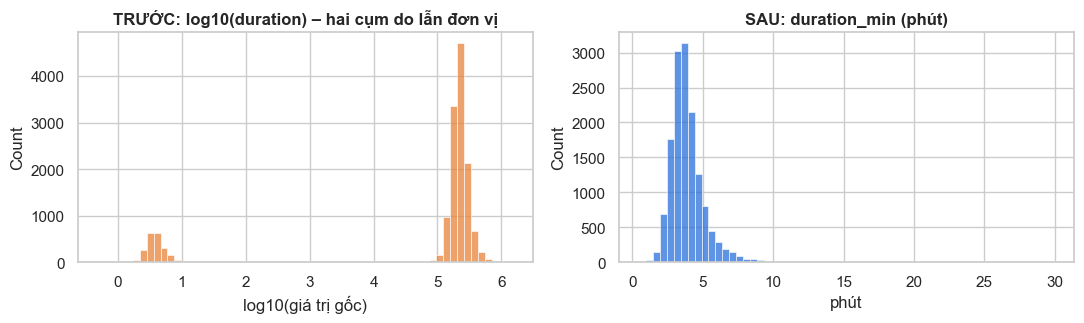

,count,mean,std,min,25%,50%,75%,max
duration_min,"14,396.0000",3.9204,1.4062,0.5017,3.1222,3.6633,4.3742,29.8860


In [4]:
d_dur = pre.fix_duration(train)
print("Dòng đơn vị phút (train):", int(d_dur["dur_was_minutes"].sum()), "| (test):", int((test[DUR] < 1000).sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(np.log10(train[DUR]), bins=60, ax=axes[0], color="#e8833a")
axes[0].set_title("TRƯỚC: log10(duration) – hai cụm do lẫn đơn vị"); axes[0].set_xlabel("log10(giá trị gốc)")
sns.histplot(d_dur["duration_min"], bins=60, ax=axes[1], color="#2a6fdb")
axes[1].set_title("SAU: duration_min (phút)"); axes[1].set_xlabel("phút")
plt.tight_layout(); plt.show()
display(d_dur["duration_min"].describe().to_frame().T)

## 3. Xử lý missing values
**Chiến lược**
- `Popularity`, `instrumentalness`: điền **median của train** (bền với outlier) **và** thêm cờ `pop_isna`, `instr_isna`.
  Ở bước EDA, việc bị thiếu liên quan mạnh tới Class (vd: `instrumentalness` thiếu ~61 % ở Class 5 nhưng gần 0 % ở Class 7) nên cờ này là một đặc trưng có ích.
- `key`: chỉ nhận 1–11, **không có 0** → NaN rất có thể là nốt 0 bị mất. Gán `key = 0` ("không rõ") và coi là một giá trị riêng, thêm cờ `key_isna`.

,missing trước,missing sau,cờ = 1
Popularity,333,0,333
key,1609,0,1609
instrumentalness,3541,0,3541


Missing còn lại ở test sau khi transform: 0


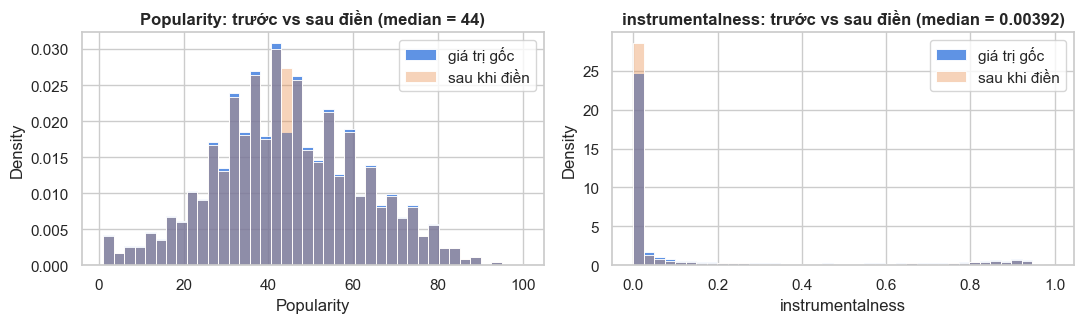

In [5]:
before = d_dur[["Popularity", "key", "instrumentalness"]].isna().sum()
d_imp = pre.impute(d_dur)
after = d_imp[["Popularity", "key", "instrumentalness"]].isna().sum()
flags = d_imp[["pop_isna", "key_isna", "instr_isna"]].sum()
display(pd.DataFrame({"missing trước": before.values, "missing sau": after.values,
                      "cờ = 1": flags.values}, index=["Popularity", "key", "instrumentalness"]))
print("Missing còn lại ở test sau khi transform:",
      int(pre.transform(test).isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, c in zip(axes, ["Popularity", "instrumentalness"]):
    sns.histplot(d_dur[c].dropna(), bins=40, ax=ax, color="#2a6fdb", label="giá trị gốc", stat="density")
    sns.histplot(d_imp[c], bins=40, ax=ax, color="#e8833a", alpha=.35, label="sau khi điền", stat="density")
    ax.set_title(f"{c}: trước vs sau điền (median = {pre.medians_[c]:.4g})"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Xử lý dữ liệu trùng lặp

In [6]:
print("Trùng toàn bộ dòng (bỏ Id, GỒM Class)      :", int(train.drop(columns=ID).duplicated().sum()))
print("Trùng toàn bộ đặc trưng (bỏ Id, Class)     :", int(train.duplicated(subset=FEAT_RAW).sum()))
print("Trùng (Artist Name, Track Name)            :", int(train.duplicated(subset=["Artist Name", "Track Name"]).sum()))

g = train.groupby(FEAT_RAW, dropna=False)[TARGET].agg(size="size", n_labels="nunique")
g = g[g["size"] > 1]
print(f"\nSố nhóm bản ghi trùng đặc trưng : {len(g):,}  (kích thước nhóm: {g['size'].value_counts().sort_index().to_dict()})")
print(f"Nhóm mà MỌI bản ghi có nhãn khác nhau: {(g['size'] == g['n_labels']).sum():,} / {len(g):,}")

Trùng toàn bộ dòng (bỏ Id, GỒM Class)      : 0
Trùng toàn bộ đặc trưng (bỏ Id, Class)     : 1081
Trùng (Artist Name, Track Name)            : 1220

Số nhóm bản ghi trùng đặc trưng : 979  (kích thước nhóm: {2: 880, 3: 96, 4: 3})
Nhóm mà MỌI bản ghi có nhãn khác nhau: 979 / 979


**Phát hiện:** không có dòng nào trùng *cả đặc trưng lẫn Class*; mọi nhóm "trùng" đều là **cùng một bài hát nhưng gắn nhiều nhãn khác nhau**
(bài hát nằm ở nhiều thể loại/playlist). Nghĩa là dữ liệu đã được loại các bản sao thật sự; phần còn lại là cấu trúc đa nhãn của dữ liệu chứ không phải "rác".

Hai phương án: **(a) giữ tất cả** hay **(b) bỏ bản trùng, giữ dòng đầu**. Vì mọi nhóm đều xung đột nhãn, phương án (b) sẽ *giữ một nhãn tuỳ ý và vứt các nhãn còn lại*.
Ta kiểm chứng bằng cross-validation chia fold **theo bài hát** (`GroupKFold`) để không bị rò rỉ giữa train và validation.

In [7]:
# group_id: mọi dòng của cùng một bài hát (Artist + Track) thuộc cùng một nhóm → dùng cho GroupKFold ở bước 05
train["group_id"] = pd.factorize(train["Artist Name"] + "||" + train["Track Name"])[0]
print("Số nhóm bài hát:", train["group_id"].nunique(), "/", len(train), "dòng")

exp_results = []
def cv_eval(name, make_pre, make_model, dedup=False, n_splits=5):
    """Macro-F1 / accuracy bằng GroupKFold. Bộ tiền xử lý được fit lại TRONG từng fold (không leak)."""
    y = train[TARGET].values
    f1s, accs, t0 = [], [], time.time()
    for tr, va in GroupKFold(n_splits=n_splits).split(train, y, train["group_id"]):
        trn = train.iloc[tr]
        if dedup:
            trn = trn[~trn.duplicated(subset=FEAT_RAW)]
        p = make_pre().fit(trn)
        m = make_model().fit(p.transform(trn), trn[TARGET])
        pred = m.predict(p.transform(train.iloc[va]))
        f1s.append(f1_score(y[va], pred, average="macro")); accs.append(accuracy_score(y[va], pred))
    exp_results.append({"thí nghiệm": name, "macro-F1": np.mean(f1s), "± std": np.std(f1s),
                        "accuracy": np.mean(accs), "giây": round(time.time() - t0)})

make_rf = lambda: RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE)
make_lr = lambda: LogisticRegression(max_iter=1000)

cv_eval("Duplicates | RF | giữ tất cả", MusicPreprocessor, make_rf)
cv_eval("Duplicates | RF | bỏ bản trùng (giữ dòng đầu)", MusicPreprocessor, make_rf, dedup=True)
display(pd.DataFrame(exp_results).set_index("thí nghiệm"))

Số nhóm bài hát: 13176 / 14396 dòng


,macro-F1,± std,accuracy,giây
thí nghiệm,,,,
Duplicates | RF | giữ tất cả,0.5734,0.0034,0.5504,6
Duplicates | RF | bỏ bản trùng (giữ dòng đầu),0.5720,0.0041,0.5492,5


In [8]:
# Quyết định
DEDUP_STRATEGY = "keep_all"        # "keep_all" (giữ tất cả) hoặc "drop_first" (bỏ bản trùng đặc trưng, giữ dòng đầu)
if DEDUP_STRATEGY == "drop_first":
    train_used = train[~train.duplicated(subset=FEAT_RAW)].copy()
else:
    train_used = train.copy()
print(f"Chiến lược: {DEDUP_STRATEGY} → train dùng để huấn luyện: {len(train_used):,} / {len(train):,} dòng")

Chiến lược: keep_all → train dùng để huấn luyện: 14,396 / 14,396 dòng


**Quyết định: giữ tất cả các dòng (`keep_all`).** Kết quả CV của hai phương án gần như bằng nhau (chênh lệch nằm trong độ lệch chuẩn), nên không có lý do để vứt thông tin nhãn.
Điều bắt buộc là **khi chia train/validation (bước 05) phải dùng `GroupKFold` theo `group_id`**; nếu chia ngẫu nhiên, cùng một bài hát nằm ở cả hai phía và điểm số bị lạc quan giả tạo.

*Ghi chú cho các bước sau:* vì dữ liệu gốc đã loại bản sao thật (cùng đặc trưng **và** cùng nhãn), một bài hát có mặt ở cả train và test (607/3.600 dòng test) có thể mang nhãn **khác** các nhãn của nó trong train.
Đây mới chỉ là giả thuyết; nếu muốn khai thác phải kiểm chứng cẩn thận ở bước Feature Engineering/Modeling.

## 5. Xử lý outliers
**Cân nhắc:** các giá trị cực trị không phải lỗi nhập liệu. Với `speechiness` và `loudness`, chúng tập trung bất thường vào một vài Class
(xem bảng bên dưới: cột "tỉ lệ trong nhóm cắt" cao gấp nhiều lần "tỉ lệ chung" – `speechiness` cực cao ↔ Class 5; `loudness` cực thấp ↔ Class 7).
Xoá các dòng này sẽ làm mất thông tin về chính những lớp nhỏ → chọn **winsorize** (cắt về phân vị 1 % và 99 % của train) thay vì xoá dòng.
Chỉ áp dụng cho `loudness`, `speechiness`, `liveness`, `duration_min`, `tempo`. `instrumentalness` bị IQR đánh dấu nhiều nhưng bản chất là phân phối hai cụm (nhạc có/không lời) nên giữ nguyên.

,lower,upper,số dòng bị cắt,%,Class chiếm nhiều nhất,tỉ lệ trong nhóm cắt (%),tỉ lệ chung của Class đó (%)
feature,,,,,,,
loudness,-22.7519,-2.1709,288,2.0006,7,32.6389,3.2023
speechiness,0.0253,0.4240,280,1.9450,5,33.5714,8.0370
liveness,0.0406,0.8590,287,1.9936,10,35.5401,27.5007
duration_min,1.8945,8.7225,288,2.0006,10,26.3889,27.5007
tempo,70.9156,193.7541,288,2.0006,10,18.0556,27.5007


,skew trước,skew sau
loudness,-1.7481,-1.4051
speechiness,3.1134,2.5277
liveness,2.1783,2.0324
duration_min,3.8043,1.4495
tempo,0.3765,0.3661


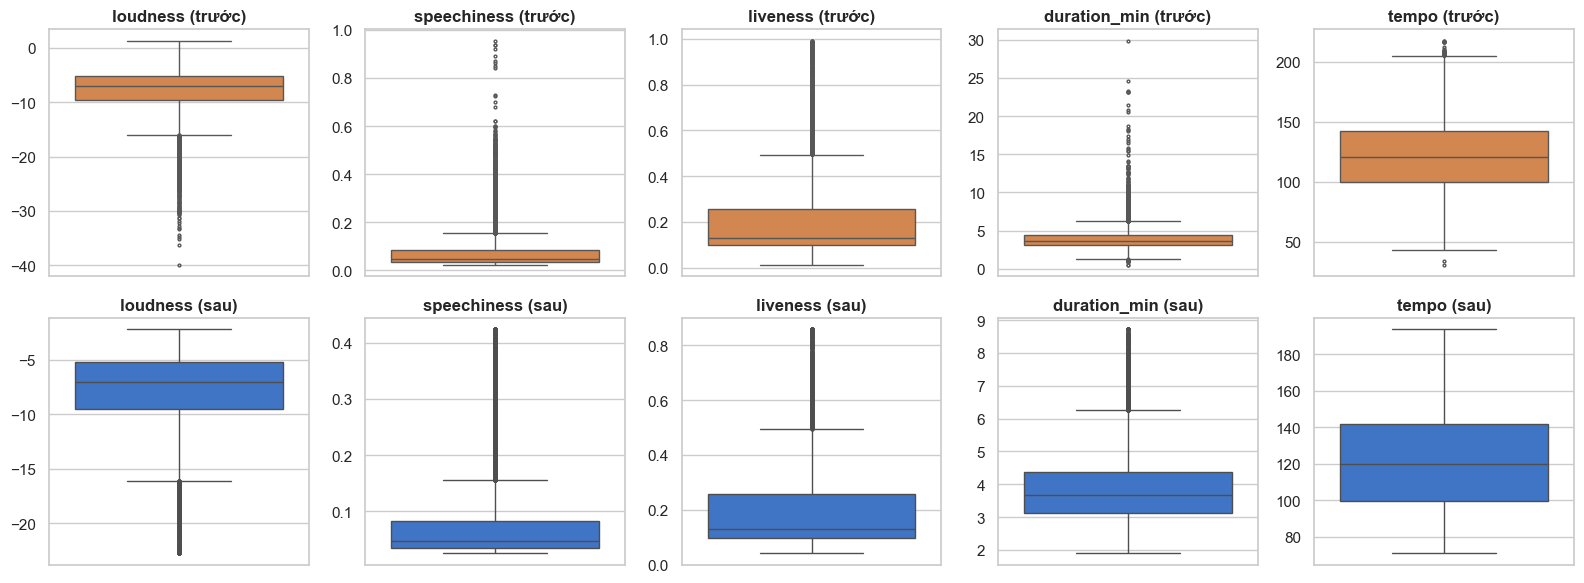

In [9]:
d_clip = pre.clip_outliers(d_imp)
base_share = train[TARGET].value_counts(normalize=True)

rows = []
for c, (lo, hi) in pre.clip_bounds_.items():
    m = (d_imp[c] < lo) | (d_imp[c] > hi)
    top = d_imp.loc[m, TARGET].value_counts(normalize=True)
    k = int(top.index[0])
    rows.append({"feature": c, "lower": lo, "upper": hi, "số dòng bị cắt": int(m.sum()), "%": m.mean() * 100,
                 "Class chiếm nhiều nhất": k, "tỉ lệ trong nhóm cắt (%)": top.iloc[0] * 100,
                 "tỉ lệ chung của Class đó (%)": base_share[k] * 100})
display(pd.DataFrame(rows).set_index("feature"))

cols = list(pre.clip_bounds_)
skew = pd.DataFrame({"skew trước": d_imp[cols].skew(), "skew sau": d_clip[cols].skew()})
display(skew)

fig, axes = plt.subplots(2, len(cols), figsize=(16, 6))
for j, c in enumerate(cols):
    sns.boxplot(y=d_imp[c], ax=axes[0, j], color="#e8833a", fliersize=2); axes[0, j].set_title(f"{c} (trước)")
    sns.boxplot(y=d_clip[c], ax=axes[1, j], color="#2a6fdb", fliersize=2); axes[1, j].set_title(f"{c} (sau)")
    axes[0, j].set_ylabel(""); axes[1, j].set_ylabel("")
plt.tight_layout(); plt.show()

In [10]:
# Kiểm chứng: cắt outlier có giúp mô hình nhạy với thang đo (Logistic Regression) không?
cv_eval("Outliers | LR | winsorize 1%-99% (mặc định)", MusicPreprocessor, make_lr)
cv_eval("Outliers | LR | KHÔNG cắt outlier", lambda: MusicPreprocessor(clip_cols=()), make_lr)
display(pd.DataFrame(exp_results[2:]).set_index("thí nghiệm"))

,macro-F1,± std,accuracy,giây
thí nghiệm,,,,
Outliers | LR | winsorize 1%-99% (mặc định),0.5252,0.0110,0.5059,4
Outliers | LR | KHÔNG cắt outlier,0.5232,0.0105,0.5039,4


Winsorize giảm rõ độ lệch của `duration_min` (3,8 → 1,5) và cho điểm cao hơn một chút nhưng **chênh lệch nhỏ** (trong khoảng nhiễu của CV).
Mô hình dựa trên cây không bị ảnh hưởng bởi outlier; bước này chủ yếu giúp các mô hình tuyến tính/khoảng cách (Logistic Regression, KNN, SVM) ổn định hơn.

## 6. Encoding dữ liệu categorical
| Cột | Bản chất | Cách encode |
|---|---|---|
| `key` | định danh nốt nhạc (không có thứ tự: nốt 11 không "lớn hơn" nốt 1) | **One-hot** `key_0` … `key_11` (`key_0` = không rõ) |
| `time_signature` | 1, 3, 4, 5 (nhịp/ô nhịp) | **One-hot** `ts_1, ts_3, ts_4, ts_5` |
| `mode` | 0/1 (thứ/trưởng) | Đã là nhị phân → giữ nguyên |
| `Artist Name`, `Track Name` | text, số giá trị khác nhau rất lớn | **Bỏ** khỏi đặc trưng (giữ `group_id` để chia fold). Frequency/Target encoding để dành cho bước Feature Engineering |
| `Id` | mã định danh | Bỏ khỏi đặc trưng (giữ lại để nộp bài) |
| `Class` | nhãn số nguyên 0–10 | Giữ nguyên, không cần LabelEncoder |

In [11]:
print("Độ đa dạng giá trị: Artist Name =", train["Artist Name"].nunique(), "| Track Name =", train["Track Name"].nunique(),
      "/", len(train), "dòng  → quá cao để one-hot")

d_enc = pre.encode(d_clip)
enc_cols = [c for c in d_enc.columns if c.startswith(("key_", "ts_")) and c not in ("key_isna",)]
print(f"\nSố cột one-hot sinh ra: {len(enc_cols)}")
display(d_enc[["key", "key_0", "key_1", "key_11", "time_signature", "ts_3", "ts_4", "mode"]].head())
print("Mỗi dòng có đúng 1 cột key_* = 1:", bool((d_enc[[f"key_{k}" for k in range(12)]].sum(axis=1) == 1).all()))

Độ đa dạng giá trị: Artist Name = 7913 | Track Name = 12455 / 14396 dòng  → quá cao để one-hot

Số cột one-hot sinh ra: 16


,key,key_0,key_1,key_11,time_signature,ts_3,ts_4,mode
0,9,0,0,0,4,0,1,0
1,11,0,0,1,4,0,1,1
2,7,0,0,0,4,0,1,1
3,0,1,0,0,3,1,0,1
4,6,0,0,0,4,0,1,0


Mỗi dòng có đúng 1 cột key_* = 1: True


## 7. Scaling dữ liệu numerical
Dùng **StandardScaler** (đưa về mean = 0, std = 1) cho 11 cột liên tục, **fit trên train** rồi áp dụng sang test.
Không scale cột one-hot, cờ missing và `mode`. Việc scale quan trọng với Logistic Regression, KNN, SVM, mạng nơ-ron; mô hình cây không cần nhưng cũng không bị hại.

trước                               sau                 \
                     mean     std      min      max    mean    std     min   
Popularity        44.5131 17.2165   1.0000 100.0000 -0.0000 1.0000 -2.5275   
danceability       0.5431  0.1655   0.0596   0.9890 -0.0000 1.0000 -2.9213   
energy             0.6624  0.2360   0.0012   1.0000  0.0000 1.0000 -2.8022   
loudness          -7.8703  3.8810 -22.7519  -2.1709  0.0000 1.0000 -3.8345   
speechiness        0.0792  0.0797   0.0253   0.4240 -0.0000 1.0000 -0.6767   
acousticness       0.2467  0.3109   0.0000   0.9960 -0.0000 1.0000 -0.7936   
instrumentalness   0.1353  0.2747   0.0000   0.9960  0.0000 1.0000 -0.4926   
liveness           0.1951  0.1556   0.0406   0.8590 -0.0000 1.0000 -0.9927   
valence            0.4864  0.2395   0.0215   0.9860  0.0000 1.0000 -1.9413   
tempo            122.6910 29.1922  70.9156 193.7541  0.0000 1.0000 -1.7737   
duration_min       3.8938  1.2010   1.8945   8.7225 -0.0000 1.0000 -1.6647   

                         
                    max  
Popularity       3.2230  
danceability     2.6940  
energy           1.4307  
loudness         1.4686  
speechiness      4.3297  
acousticness     2.4099  
instrumentalness 3.1340  
liveness         4.2663  
valence          2.0864  
tempo            2.4344  
duration_min     4.0208

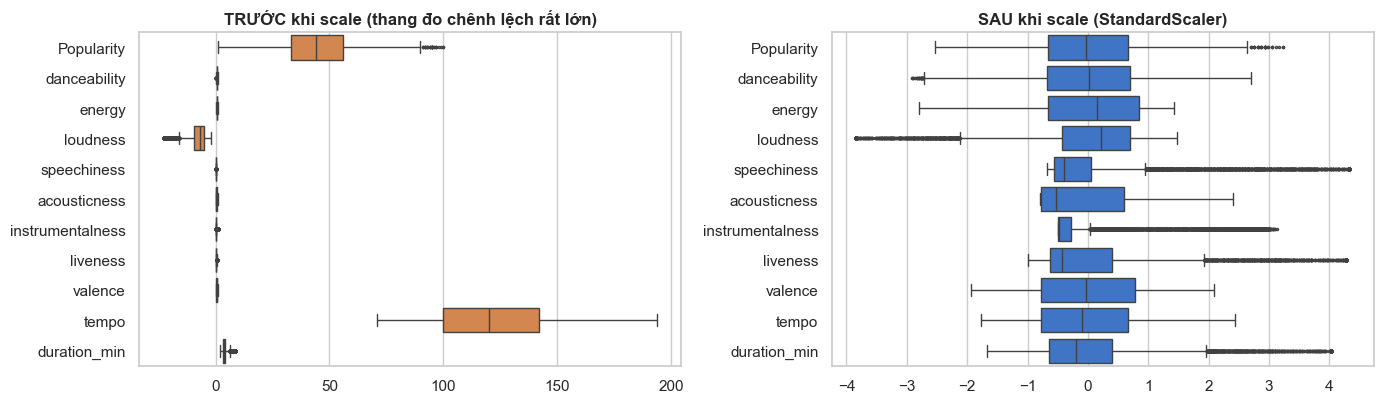

In [12]:
d_sc = pre.scale_features(d_enc)
cmp = pd.concat({"trước": d_enc[CONT_COLS].agg(["mean", "std", "min", "max"]).T,
                 "sau": d_sc[CONT_COLS].agg(["mean", "std", "min", "max"]).T}, axis=1)
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.boxplot(data=d_enc[CONT_COLS], orient="h", ax=axes[0], color="#e8833a", fliersize=1.5)
axes[0].set_title("TRƯỚC khi scale (thang đo chênh lệch rất lớn)")
sns.boxplot(data=d_sc[CONT_COLS], orient="h", ax=axes[1], color="#2a6fdb", fliersize=1.5)
axes[1].set_title("SAU khi scale (StandardScaler)")
plt.tight_layout(); plt.show()

In [13]:
cv_eval("Scaling | LR | StandardScaler (mặc định)", MusicPreprocessor, make_lr)
cv_eval("Scaling | LR | KHÔNG scale", lambda: MusicPreprocessor(scale=False), make_lr)
display(pd.DataFrame(exp_results[4:]).set_index("thí nghiệm"))

,macro-F1,± std,accuracy,giây
thí nghiệm,,,,
Scaling | LR | StandardScaler (mặc định),0.5252,0.0110,0.5059,4
Scaling | LR | KHÔNG scale,0.4824,0.0113,0.4818,20


Với Logistic Regression, **không scale cho điểm thấp hơn rõ rệt** (và hội tụ chậm hơn nhiều) → scaling là cần thiết cho nhóm mô hình tuyến tính/khoảng cách.

## 8. Pipeline hoàn chỉnh, kiểm tra và lưu kết quả

In [14]:
# Fit lần cuối trên train_used, rồi transform train & test
pre_final = MusicPreprocessor().fit(train_used)
X_train = pre_final.transform(train_used)
X_test = pre_final.transform(test)

# --- Kiểm tra chất lượng ---
assert list(X_train.columns) == list(X_test.columns) == FEATURE_COLS,  "train/test lệch cột"
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "còn NaN"
assert np.isfinite(X_train.values).all() and np.isfinite(X_test.values).all(), "có inf"
assert len(X_train) == len(train_used) and len(X_test) == len(test), "lệch số dòng"
chain = pre_final.scale_features(pre_final.encode(pre_final.clip_outliers(
        pre_final.impute(pre_final.fix_duration(train_used)))))[FEATURE_COLS]
assert np.allclose(chain.values, X_train.values), "transform() không khớp chuỗi các bước"
print("✔ Không NaN/inf | train & test cùng cột | transform() khớp từng bước")
print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}  |  số đặc trưng: {len(FEATURE_COLS)}")

# Mean/std của test sau scale sẽ không đúng 0/1 (vì dùng thống kê của train) – điều này là bình thường
display(pd.DataFrame({"mean train": X_train[CONT_COLS].mean(), "std train": X_train[CONT_COLS].std(),
                      "mean test": X_test[CONT_COLS].mean(), "std test": X_test[CONT_COLS].std()}))

✔ Không NaN/inf | train & test cùng cột | transform() khớp từng bước
X_train: (14396, 32)  |  X_test: (3600, 32)  |  số đặc trưng: 32


,mean train,std train,mean test,std test
Popularity,-0.0000,1.0000,-0.0038,1.0008
danceability,-0.0000,1.0000,0.0099,1.0226
energy,0.0000,1.0000,0.0075,0.9875
loudness,0.0000,1.0000,-0.0120,0.9910
speechiness,-0.0000,1.0000,-0.0221,0.9373
acousticness,-0.0000,1.0000,0.0054,0.9955
instrumentalness,0.0000,1.0000,0.0009,1.0027
liveness,-0.0000,1.0000,0.0124,0.9982
valence,0.0000,1.0000,-0.0036,1.0151
tempo,0.0000,1.0000,-0.0125,1.0054


In [15]:
# Lưu dữ liệu đã xử lý
OUT_DIR.mkdir(exist_ok=True)
train_out = pd.concat([train_used[[ID]].reset_index(drop=True), X_train.reset_index(drop=True),
                       train_used[["group_id", TARGET]].reset_index(drop=True)], axis=1)
test_out = pd.concat([test[[ID]].reset_index(drop=True), X_test.reset_index(drop=True)], axis=1)
train_out.to_csv(OUT_DIR / "train_processed.csv", index=False)
test_out.to_csv(OUT_DIR / "test_processed.csv", index=False)
joblib.dump(pre_final, OUT_DIR / "preprocessor.joblib")

print("Đã lưu vào:", OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    print(f"  - {f.name:<24} {f.stat().st_size / 1024:>9,.0f} KB")
display(train_out.head(3))

Đã lưu vào: d:\May Hoc\CK_ML\MAY_HOC_NHOM\Challenge\Challenge 2\DATA_CHALLENGE2\processed
  - preprocessor.joblib              2 KB
  - test_processed.csv             936 KB
  - train_processed.csv          3,834 KB


,Id,Popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_min,mode,pop_isna,key_isna,instr_isna,dur_was_minutes,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,ts_1,ts_3,ts_4,ts_5,group_id,Class
0,1,-0.4364,-1.2634,-0.5358,0.3147,-0.5160,0.4222,-0.4783,-0.5724,-1.0497,1.0187,-0.3980,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,9
1,2,1.3062,1.0990,0.3584,0.5992,0.1055,-0.7061,-0.3222,-0.5852,-0.4442,0.3504,-0.5783,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,6
2,3,-0.0298,0.2471,0.6000,0.4577,-0.2172,-0.7905,1.8195,0.5714,0.6206,1.2765,-1.0074,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,2,10


## 9. Tổng kết

| Bước | Quyết định | Căn cứ |
|---|---|---|
| **Duration** | Quy đổi về phút (`duration_min`) + cờ `dur_was_minutes` | 2.075 dòng train / 505 dòng test đang ở đơn vị phút |
| **Missing** | Cờ `pop_isna`, `key_isna`, `instr_isna`; điền median (`Popularity` = 44, `instrumentalness` = 0,00392); `key` NaN → 0 | Missing liên quan mạnh tới Class nên cờ là thông tin; median bền với outlier |
| **Duplicates** | **Giữ tất cả** dòng; tạo `group_id` theo (Artist, Track) | Không có dòng nào trùng cả đặc trưng lẫn Class; 979 nhóm trùng đều là cùng bài hát khác nhãn. CV `GroupKFold`: giữ hay bỏ cho macro-F1 gần như bằng nhau (≈ 0,574) |
| **Outliers** | Winsorize p1–p99 cho `loudness`, `speechiness`, `liveness`, `duration_min`, `tempo`; **không xoá dòng** | Outlier `speechiness`/`loudness` tập trung vào Class 5/7 → xoá sẽ mất thông tin; skew `duration_min` giảm 3,8 → 1,4; cải thiện LR rất nhỏ (≈ 0,519 → 0,521) |
| **Encoding** | One-hot `key` (12 cột), `time_signature` (4 cột); `mode` giữ nguyên; bỏ `Artist Name`, `Track Name`, `Id` | `key`/`time_signature` không có thứ tự; text có độ đa dạng quá cao |
| **Scaling** | StandardScaler cho 11 cột liên tục (fit trên train) | Với Logistic Regression: không scale → macro-F1 ≈ 0,481 so với ≈ 0,521 khi có scale |

**Kết quả:** `X_train` 14.396 × 32 và `X_test` 3.600 × 32, không còn NaN/inf, train và test cùng cột.
Đã lưu vào `DATA_CHALLENGE2/processed/`: `train_processed.csv` (có thêm `group_id`, `Class`), `test_processed.csv` và `preprocessor.joblib`.

### Lưu ý cho các bước sau
1. **Bước 05 (Pipeline + Split):** dùng `GroupKFold` theo `group_id`, và đặt `MusicPreprocessor` **bên trong** `Pipeline` để median, ngưỡng cắt, scaler được fit lại trong từng fold (không rò rỉ). Khi huấn luyện **bỏ cột `Id` và `group_id`**.
2. **Bước 04 (Feature Engineering):** có thể thử frequency encoding cho `Artist Name`, độ dài tên bài hát, các đặc trưng kết hợp (vd: `energy` × `loudness`).
3. Kết quả CV ở các mục 4, 5, 7 chỉ dùng để chọn cách xử lý, **không phải** điểm mô hình cuối cùng.


## 10. Ghi nhật ký thí nghiệm
Nhớ sửa `RUNNER` ở ô đầu notebook và điền `NOTES` bằng nhận xét của bạn trước khi chạy ô này.

In [16]:
NOTES = "Điền nhận xét của bạn ở đây (vd: quyết định xử lý, điểm cần lưu ý cho bước 04/05)."

log.step("Dữ liệu vào", train_rows=len(train), test_rows=len(test), n_raw_features=len(FEAT_RAW))
log.step("Duration", train_rows_in_minutes=int(d_dur["dur_was_minutes"].sum()), action="quy đổi về phút")
log.step("Missing", medians=pre_final.medians_, action="cờ *_isna + median (Popularity, instrumentalness), key NaN→0")
log.step("Duplicates", dup_groups=len(g), exact_dup_incl_class=int(train.drop(columns=[ID, "group_id"]).duplicated().sum()),
         strategy=DEDUP_STRATEGY, rows_used=len(train_used))
log.step("Outliers", method="winsorize p1-p99 (fit trên train)", columns=list(pre_final.clip_bounds_))
log.step("Encoding", key="one-hot (12 cột, key_0 = không rõ)", time_signature="one-hot (4 cột)",
         dropped="Artist Name, Track Name, Id")
log.step("Scaling", method="StandardScaler (fit trên train)", n_scaled=len(CONT_COLS))
for r in exp_results:
    log.step("CV: " + r["thí nghiệm"], macro_F1=round(r["macro-F1"], 4), std=round(r["± std"], 4),
             accuracy=round(r["accuracy"], 4))
log.step("Đầu ra", X_train=X_train.shape, X_test=X_test.shape, n_features=len(FEATURE_COLS),
         files="train_processed.csv, test_processed.csv, preprocessor.joblib")
log.save(notes=NOTES)

✅ Đã ghi nhật ký: experiment_log.csv (thêm 1 dòng) và 03_Data_Preprocessing_20261112_102838_Tô-Doanh-Quang-Khu.md


WindowsPath('d:/May Hoc/CK_ML/MAY_HOC_NHOM/Challenge/Challenge 2/logs/03_Data_Preprocessing_20261112_102838_Tô-Doanh-Quang-Khu.md')